In [5]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Visualization style
sns.set_style('whitegrid')

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
df = pd.read_csv("online_retail_II.csv")

In [4]:
print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  str    
 1   StockCode    1067371 non-null  str    
 2   Description  1062989 non-null  str    
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  str    
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 136.6 MB


In [7]:
df.describe()

,Quantity,Price,Customer ID
count,1.067371e+06,1.067371e+06,824364.000000
mean,9.938898e+00,4.649388e+00,15324.638504
std,1.727058e+02,1.235531e+02,1697.464450
min,-8.099500e+04,-5.359436e+04,12346.000000
25%,1.000000e+00,1.250000e+00,13975.000000
50%,3.000000e+00,2.100000e+00,15255.000000
75%,1.000000e+01,4.150000e+00,16797.000000
max,8.099500e+04,3.897000e+04,18287.000000


In [8]:
print(df.columns.tolist())

['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


In [9]:
df.isnull().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [10]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 34335


In [11]:
# Check missing values in each column

missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

# Calculate missing percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("\nMissing Percentage:")
print(missing_percentage.round(2))

Missing Values:
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

Missing Percentage:
Invoice         0.00
StockCode       0.00
Description     0.41
Quantity        0.00
InvoiceDate     0.00
Price           0.00
Customer ID    22.77
Country         0.00
dtype: float64


In [12]:
# Check duplicate records

duplicate_count = df.duplicated().sum()

print("Total duplicate records:", duplicate_count)

Total duplicate records: 34335


In [13]:
# Check negative and zero quantities

print("Negative Quantity:", (df['Quantity'] < 0).sum())

print("Zero Quantity:", (df['Quantity'] == 0).sum())

# Check negative and zero prices

print("Negative Price:", (df['Price'] < 0).sum())

print("Zero Price:", (df['Price'] == 0).sum())

Negative Quantity: 22950
Zero Quantity: 0
Negative Price: 5
Zero Price: 6202


In [14]:
# Convert InvoiceDate to datetime format

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Verify the conversion

print("InvoiceDate datatype:", df['InvoiceDate'].dtype)

df[['Invoice', 'InvoiceDate']].head()

InvoiceDate datatype: datetime64[us]


,Invoice,InvoiceDate
0,489434,2009-12-01 07:45:00
1,489434,2009-12-01 07:45:00
2,489434,2009-12-01 07:45:00
3,489434,2009-12-01 07:45:00
4,489434,2009-12-01 07:45:00


In [15]:
# Create a copy of the original dataset

df_clean = df.copy()

# Remove transactions without Customer ID
df_clean = df_clean.dropna(subset=['Customer ID'])

# Remove cancelled invoices
df_clean = df_clean[~df_clean['Invoice'].str.startswith('C')]

# Remove negative and zero quantities
df_clean = df_clean[df_clean['Quantity'] > 0]

# Remove negative and zero prices
df_clean = df_clean[df_clean['Price'] > 0]

# Remove duplicate records
df_clean = df_clean.drop_duplicates()

# Reset index
df_clean = df_clean.reset_index(drop=True)

print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)

Original Dataset Shape: (1067371, 8)
Cleaned Dataset Shape: (779425, 8)


In [16]:
# Calculate total purchase amount

df_clean['TotalPrice'] = (
    df_clean['Quantity'] * df_clean['Price']
)

# Display the result

df_clean[['Customer ID', 'Quantity',
          'Price', 'TotalPrice']].head()

,Customer ID,Quantity,Price,TotalPrice
0,13085.0,12,6.95,83.4
1,13085.0,12,6.75,81.0
2,13085.0,12,6.75,81.0
3,13085.0,48,2.10,100.8
4,13085.0,24,1.25,30.0


In [17]:
# Set reference date

reference_date = df_clean['InvoiceDate'].max() + pd.Timedelta(days=1)

print("Reference Date:", reference_date)

Reference Date: 2011-12-10 12:50:00


In [18]:
# Group transactions by Customer ID

rfm = df_clean.groupby('Customer ID').agg({

    'InvoiceDate': lambda x: (
        reference_date - x.max()
    ).days,

    'Invoice': 'nunique',

    'TotalPrice': 'sum'

})

# Rename columns

rfm.rename(columns={

    'InvoiceDate': 'Recency',
    'Invoice': 'Frequency',
    'TotalPrice': 'Monetary'

}, inplace=True)

# Display RFM table

rfm.head()

,Recency,Frequency,Monetary
Customer ID,,,
12346.0,326,12,77556.46
12347.0,2,8,4921.53
12348.0,75,5,2019.40
12349.0,19,4,4428.69
12350.0,310,1,334.40


In [19]:
# Calculate Average Purchase Value

rfm['AveragePurchaseValue'] = (
    rfm['Monetary'] / rfm['Frequency']
)

# Historical Customer Lifetime Value
# Total revenue generated by each customer

rfm['CustomerLifetimeValue'] = rfm['Monetary']

# Display customer metrics

rfm.head()

,Recency,Frequency,Monetary,AveragePurchaseValue,CustomerLifetimeValue
Customer ID,,,,,
12346.0,326,12,77556.46,6463.038333,77556.46
12347.0,2,8,4921.53,615.191250,4921.53
12348.0,75,5,2019.40,403.880000,2019.40
12349.0,19,4,4428.69,1107.172500,4428.69
12350.0,310,1,334.40,334.400000,334.40


In [20]:
# Check dataset dimensions

print("Total Customers:", len(rfm))

print("\nRFM Dataset Information:")
print(rfm.info())

print("\nStatistical Summary:")
display(rfm.describe().round(2))

Total Customers: 5878

RFM Dataset Information:
<class 'pandas.DataFrame'>
Index: 5878 entries, 12346.0 to 18287.0
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Recency                5878 non-null   int64  
 1   Frequency              5878 non-null   int64  
 2   Monetary               5878 non-null   float64
 3   AveragePurchaseValue   5878 non-null   float64
 4   CustomerLifetimeValue  5878 non-null   float64
dtypes: float64(3), int64(2)
memory usage: 275.5 KB
None

Statistical Summary:


,Recency,Frequency,Monetary,AveragePurchaseValue,CustomerLifetimeValue
count,5878.00,5878.00,5878.00,5878.00,5878.00
mean,201.33,6.29,2955.90,385.18,2955.90
std,209.34,13.01,14440.85,1214.29,14440.85
min,1.00,1.00,2.95,2.95,2.95
25%,26.00,1.00,342.28,176.68,342.28
50%,96.00,3.00,867.74,279.24,867.74
75%,380.00,7.00,2248.30,414.90,2248.30
max,739.00,398.00,580987.04,84236.25,580987.04


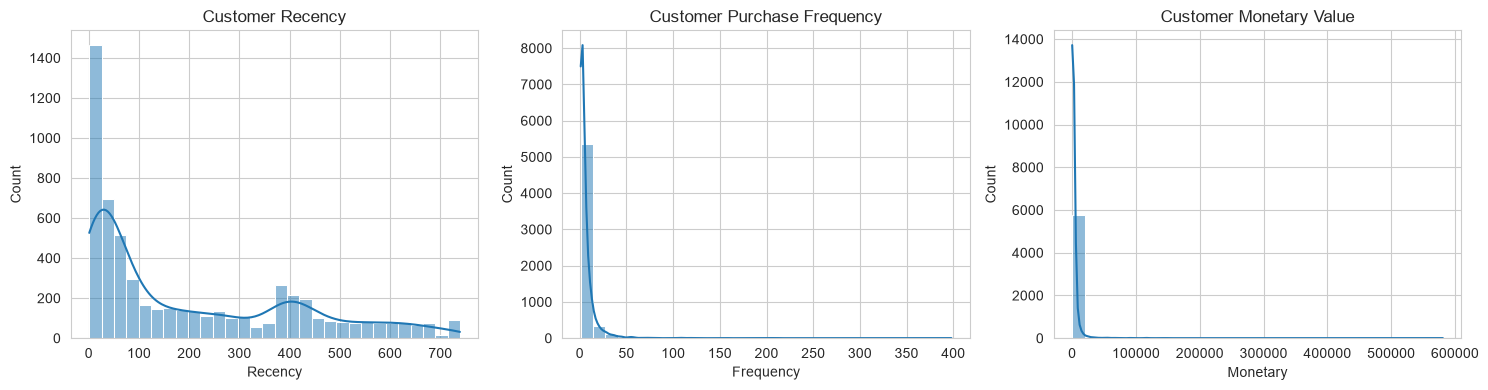

In [21]:
# Plot RFM distributions

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
sns.histplot(rfm['Recency'], bins=30, kde=True)
plt.title('Customer Recency')

plt.subplot(1, 3, 2)
sns.histplot(rfm['Frequency'], bins=30, kde=True)
plt.title('Customer Purchase Frequency')

plt.subplot(1, 3, 3)
sns.histplot(rfm['Monetary'], bins=30, kde=True)
plt.title('Customer Monetary Value')

plt.tight_layout()
plt.show()

In [22]:
# Select features for clustering

rfm_features = rfm[['Recency', 'Frequency', 'Monetary']].copy()

# Check selected features

print("Selected RFM Features:")
display(rfm_features.head())

print("\nFeature Shape:", rfm_features.shape)

Selected RFM Features:


,Recency,Frequency,Monetary
Customer ID,,,
12346.0,326,12,77556.46
12347.0,2,8,4921.53
12348.0,75,5,2019.40
12349.0,19,4,4428.69
12350.0,310,1,334.40



Feature Shape: (5878, 3)


In [23]:
# Apply log transformation

rfm_log = np.log1p(rfm_features)

# Display transformed data

display(rfm_log.head())

,Recency,Frequency,Monetary
Customer ID,,,
12346.0,5.789960,2.564949,11.258774
12347.0,1.098612,2.197225,8.501578
12348.0,4.330733,1.791759,7.611051
12349.0,2.995732,1.609438,8.396085
12350.0,5.739793,0.693147,5.815324


In [24]:
from sklearn.preprocessing import StandardScaler

# Create StandardScaler object

scaler = StandardScaler()

# Normalize the RFM features

rfm_scaled = scaler.fit_transform(rfm_log)

# Convert into DataFrame

rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=['Recency', 'Frequency', 'Monetary'],
    index=rfm.index
)

# Display normalized data

display(rfm_scaled.head())

,Recency,Frequency,Monetary
Customer ID,,,
12346.0,0.856701,1.254496,3.206219
12347.0,-2.151979,0.800166,1.215993
12348.0,-0.079138,0.299207,0.573185
12349.0,-0.935308,0.073946,1.139846
12350.0,0.824527,-1.058146,-0.723024


In [25]:
# Check mean and standard deviation

print("Feature Means:")
print(rfm_scaled.mean().round(2))

print("\nFeature Standard Deviations:")
print(rfm_scaled.std().round(2))

Feature Means:
Recency     -0.0
Frequency    0.0
Monetary     0.0
dtype: float64

Feature Standard Deviations:
Recency      1.0
Frequency    1.0
Monetary     1.0
dtype: float64


In [26]:
from sklearn.cluster import KMeans

# Calculate WCSS for different cluster numbers

wcss = []

for k in range(1, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)

    wcss.append(kmeans.inertia_)

print("WCSS Values:")
print(wcss)

WCSS Values:
[17634.000000000004, 8588.985343295873, 6354.3431534260735, 4921.2333452738085, 4099.10607877831, 3554.696268860983, 3194.5009715515407, 2902.4338849526234, 2656.562327908442, 2467.3784663539072]


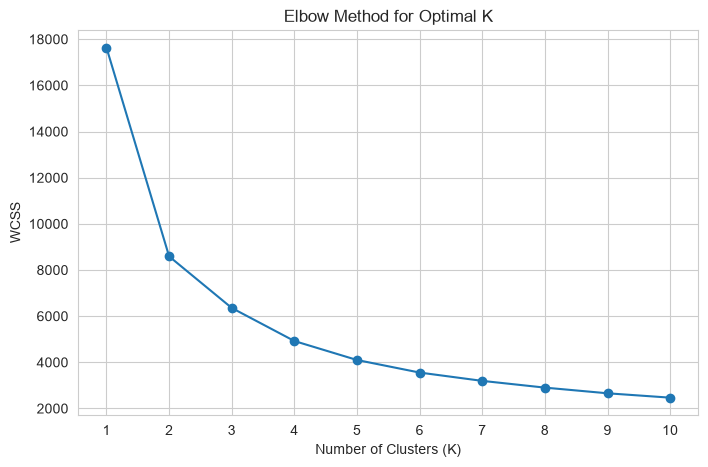

In [27]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker='o'
)

plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.xticks(range(1, 11))
plt.grid(True)

plt.show()

In [28]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 7):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(rfm_scaled)

    score = silhouette_score(rfm_scaled, labels)

    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.4386
K = 3, Silhouette Score = 0.3477
K = 4, Silhouette Score = 0.3650
K = 5, Silhouette Score = 0.3425
K = 6, Silhouette Score = 0.3348


In [29]:
# Apply K-Means clustering with K = 2

kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Fit the model and assign cluster labels

rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

# Display the results

print("K-Means clustering completed!")

display(rfm.head(10))

K-Means clustering completed!


,Recency,Frequency,Monetary,AveragePurchaseValue,CustomerLifetimeValue,Cluster
Customer ID,,,,,,
12346.0,326,12,77556.46,6463.038333,77556.46,1
12347.0,2,8,4921.53,615.191250,4921.53,1
12348.0,75,5,2019.40,403.880000,2019.40,1
12349.0,19,4,4428.69,1107.172500,4428.69,1
12350.0,310,1,334.40,334.400000,334.40,0
12351.0,375,1,300.93,300.930000,300.93,0
12352.0,36,10,2849.84,284.984000,2849.84,1
12353.0,204,2,406.76,203.380000,406.76,0
12354.0,232,1,1079.40,1079.400000,1079.40,0


In [30]:
# Count customers in each cluster

cluster_counts = rfm['Cluster'].value_counts().sort_index()

print("Number of customers in each cluster:")
print(cluster_counts)

Number of customers in each cluster:
Cluster
0    3558
1    2320
Name: count, dtype: int64


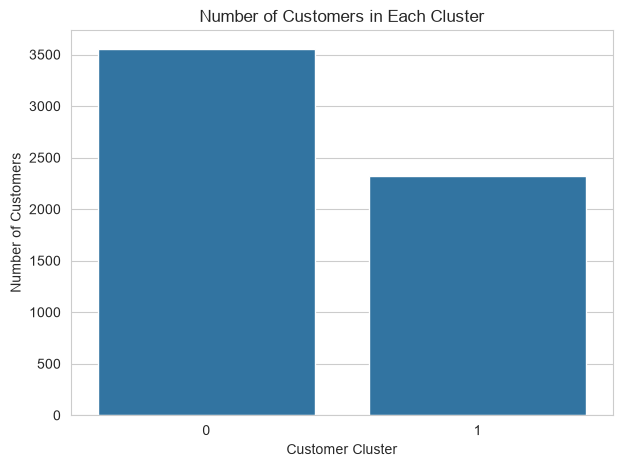

In [31]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=rfm.reset_index(),
    x='Cluster'
)

plt.title('Number of Customers in Each Cluster')
plt.xlabel('Customer Cluster')
plt.ylabel('Number of Customers')

plt.show()

In [32]:
# Calculate cluster-wise average values

cluster_profile = rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean',
    'AveragePurchaseValue': 'mean',
    'CustomerLifetimeValue': 'mean'
}).round(2)

print("Customer Cluster Profiles:")

display(cluster_profile)

Customer Cluster Profiles:


,Recency,Frequency,Monetary,AveragePurchaseValue,CustomerLifetimeValue
Cluster,,,,,
0,299.65,2.10,614.34,316.89,614.34
1,50.56,12.72,6546.97,489.91,6546.97


In [33]:
cluster_median = rfm.groupby('Cluster')[
    ['Recency', 'Frequency', 'Monetary']
].median().round(2)

display(cluster_median)

,Recency,Frequency,Monetary
Cluster,,,
0,289.5,2.0,415.80
1,24.0,8.0,2861.48


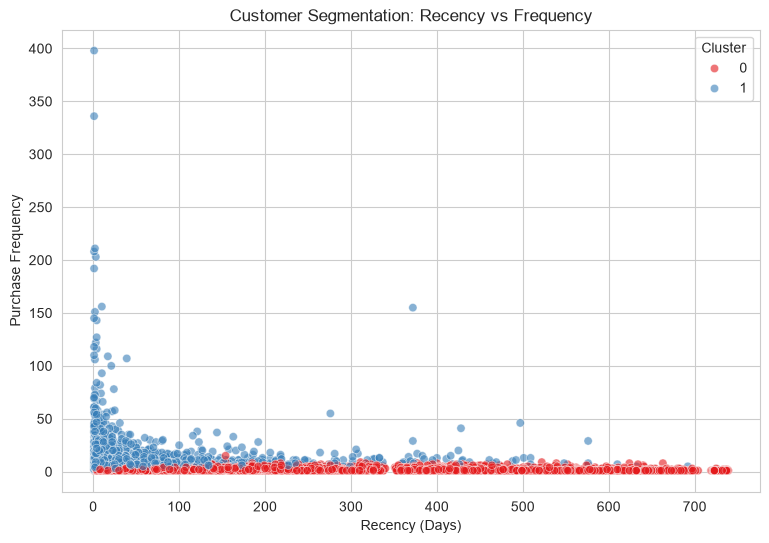

In [34]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Frequency',
    hue='Cluster',
    palette='Set1',
    alpha=0.6
)

plt.title('Customer Segmentation: Recency vs Frequency')
plt.xlabel('Recency (Days)')
plt.ylabel('Purchase Frequency')

plt.show()

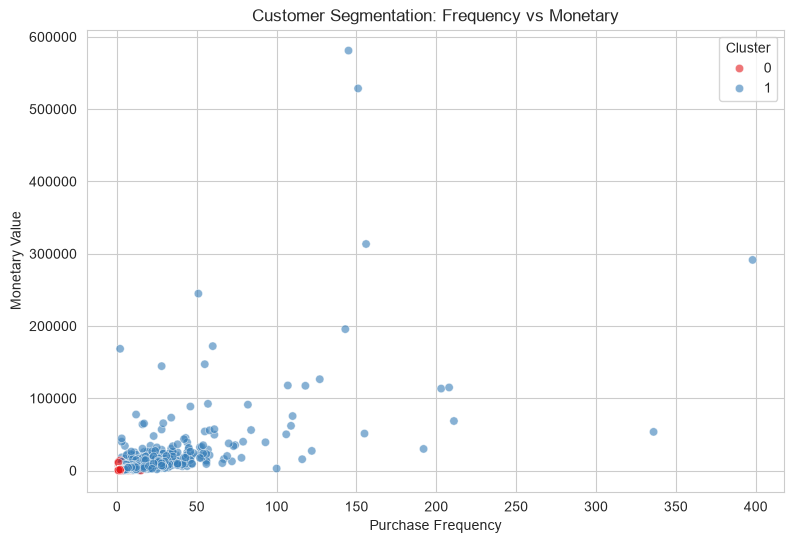

In [35]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm,
    x='Frequency',
    y='Monetary',
    hue='Cluster',
    palette='Set1',
    alpha=0.6
)

plt.title('Customer Segmentation: Frequency vs Monetary')
plt.xlabel('Purchase Frequency')
plt.ylabel('Monetary Value')

plt.show()

In [36]:
# Assign meaningful customer segment names

segment_names = {
    0: 'At-Risk / Low-Value Customers',
    1: 'Active / High-Value Customers'
}

rfm['Customer_Segment'] = rfm['Cluster'].map(segment_names)

# Display customer segments

display(
    rfm[['Recency', 'Frequency', 'Monetary',
         'Cluster', 'Customer_Segment']].head(10)
)

,Recency,Frequency,Monetary,Cluster,Customer_Segment
Customer ID,,,,,
12346.0,326,12,77556.46,1,Active / High-Value Customers
12347.0,2,8,4921.53,1,Active / High-Value Customers
12348.0,75,5,2019.40,1,Active / High-Value Customers
12349.0,19,4,4428.69,1,Active / High-Value Customers
12350.0,310,1,334.40,0,At-Risk / Low-Value Customers
12351.0,375,1,300.93,0,At-Risk / Low-Value Customers
12352.0,36,10,2849.84,1,Active / High-Value Customers
12353.0,204,2,406.76,0,At-Risk / Low-Value Customers
12354.0,232,1,1079.40,0,At-Risk / Low-Value Customers


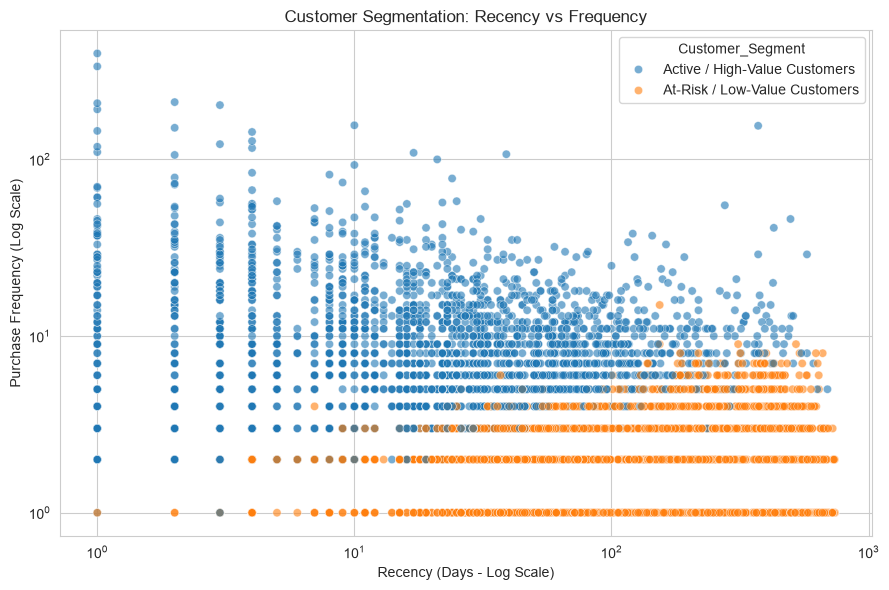

In [37]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Frequency',
    hue='Customer_Segment',
    alpha=0.6
)

plt.xscale('log')
plt.yscale('log')

plt.title('Customer Segmentation: Recency vs Frequency')
plt.xlabel('Recency (Days - Log Scale)')
plt.ylabel('Purchase Frequency (Log Scale)')

plt.tight_layout()
plt.show()

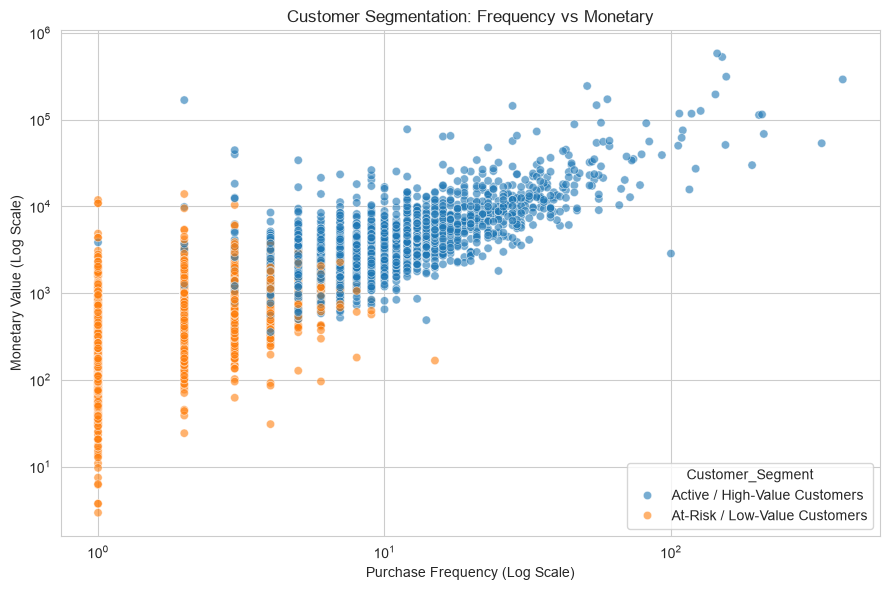

In [38]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm,
    x='Frequency',
    y='Monetary',
    hue='Customer_Segment',
    alpha=0.6
)

plt.xscale('log')
plt.yscale('log')

plt.title('Customer Segmentation: Frequency vs Monetary')
plt.xlabel('Purchase Frequency (Log Scale)')
plt.ylabel('Monetary Value (Log Scale)')

plt.tight_layout()
plt.show()

In [40]:
# Save customer segmentation results

rfm.to_csv("customer_segments.csv")

# Save cluster profile

cluster_profile.to_csv("cluster_profile.csv")

print("Customer segmentation results saved successfully!")

Customer segmentation results saved successfully!
